# SkyFinder × DIR — Step 1: get the data onto Colab

This notebook: clones the project repo → downloads all SkyFinder images (resized to 256 px) →
caches them on Google Drive so you only download once → runs `prepare_data.py` → sanity-checks the result.

**Before running:** Runtime → Change runtime type → **T4 GPU** (not needed for this notebook, but the next one trains).

In [ ]:
!nvidia-smi -L || echo "No GPU attached (fine for data prep, needed for training)"

## 1. Settings — edit these

In [7]:
GITHUB_USER = "alexander-lio"          # <-- edit
REPO_NAME   = "imbalanced-regressiion-on-skyfinder"  # <-- edit to match the exact GitHub repo name
PRIVATE_REPO = False    # if True, add a GitHub token in Colab: key icon (Secrets) -> name it GITHUB_TOKEN

REPO_DIR   = "/content/repo"
IMAGES_DIR = "/content/images"                 # fast local Colab disk (wiped when the session ends)
DRIVE_CACHE = "/content/drive/MyDrive/skyfinder_cache"   # persistent copy on your Google Drive

## 2. Mount Google Drive (for the image cache)

In [3]:
from google.colab import drive
drive.mount("/content/drive")
import os; os.makedirs(DRIVE_CACHE, exist_ok=True)

Mounted at /content/drive


## 3. Clone (or update) the repo

In [8]:
import os, subprocess
if PRIVATE_REPO:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    url = f"https://{token}@github.com/{GITHUB_USER}/{REPO_NAME}.git"
else:
    url = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

if os.path.exists(REPO_DIR):
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)
else:
    subprocess.run(["git", "clone", "-q", url, REPO_DIR], check=True)
%cd {REPO_DIR}
!git log --oneline | head -5
!ls

Cloning https://github.com/alexander-lio/imbalanced-regression-on-skyfinder.git into /content/repo...
/content/repo
e29dcd0 Add data prep scripts, EDA, and project docs
1119ef2 Add upstream agedb-dir code from YyzHarry/imbalanced-regression (unmodified)
dir_skyfinder  notebooks  README.md	    results
eda	       NOTES.md   requirements.txt  scripts


In [9]:
# Colab already has torch/torchvision; this only installs what's missing.
!pip install -q -r requirements.txt

## 4. Check the script flags
Claude Code wrote these scripts, so confirm the flag names below match what `--help` prints.
If they differ, adjust the commands in steps 5–6.

In [10]:
!python scripts/download_images.py --help
!python scripts/prepare_data.py --help

usage: download_images.py [-h] [--metadata METADATA] [--metadata_only]
                          [--images_dir IMAGES_DIR] [--resize RESIZE]

Download SkyFinder metadata and/or camera images.

options:
  -h, --help            show this help message and exit
  --metadata METADATA   Path to save / find the metadata CSV
  --metadata_only       Download only the metadata CSV, skip images
  --images_dir IMAGES_DIR
                        Root directory for extracted camera images
  --resize RESIZE       After extracting, resize so short side = N px (JPEG
                        q90, overwrite in place)
usage: prepare_data.py [-h] [--metadata METADATA] [--images_dir IMAGES_DIR]
                       [--out OUT] [--seed SEED] [--test_per_bin TEST_PER_BIN]
                       [--val_per_bin VAL_PER_BIN]

Build data/skyfinder.csv from SkyFinder metadata.

options:
  -h, --help            show this help message and exit
  --metadata METADATA   Path to complete_table_with_mcr.csv
  --images_d

## 5. Get the images (download once, then reuse from Drive)
First run: downloads ~50 camera zips (a few GB before resizing) — expect roughly 20–60 min.
It then saves one compressed tarball to your Drive. Later sessions just unpack that (a couple of minutes).

In [11]:
import os
TAR = f"{DRIVE_CACHE}/skyfinder_images_256.tar"

# metadata CSV (gitignored, so fetch it here)
!python scripts/download_images.py --metadata_only --metadata data/complete_table_with_mcr.csv

if os.path.exists(TAR):
    print("Found cached images on Drive -> extracting")
    !mkdir -p {IMAGES_DIR} && tar -xf "{TAR}" -C {IMAGES_DIR}
else:
    print("No cache yet -> downloading all cameras")
    !python scripts/download_images.py --metadata data/complete_table_with_mcr.csv --images_dir {IMAGES_DIR} --resize 256
    print("Saving cache to Drive ...")
    !tar -cf "{TAR}" -C {IMAGES_DIR} .
!du -sh {IMAGES_DIR}; ls {IMAGES_DIR} | wc -l

Done (metadata only).
No cache yet -> downloading all cameras
Metadata already exists: data/complete_table_with_mcr.csv

53 cameras found in metadata.
  Camera 65: extracted 3252 files
    Resized 3252 images (short side -> 256 px)
  Camera 75: extracted 3220 files
    Resized 3220 images (short side -> 256 px)
  Camera 162: extracted 3257 files
    Resized 3257 images (short side -> 256 px)
  Camera 204: extracted 2494 files
    Resized 2494 images (short side -> 256 px)
  Camera 260: extracted 3238 files
    Resized 3238 images (short side -> 256 px)
  Camera 623: extracted 3790 files
    Resized 3790 images (short side -> 256 px)
  Camera 684: extracted 4094 files
    Resized 4094 images (short side -> 256 px)
  Camera 858: extracted 200 files
    Resized 200 images (short side -> 256 px)
  Camera 861: extracted 1364 files
    Resized 1362 images (short side -> 256 px)
  Camera 1093: extracted 870 files
    Resized 870 images (short side -> 256 px)
  Camera 3297: extracted 1781 file

In [12]:
from PIL import Image, ImageFile
import glob, collections

repaired, broken = [], []
for p in glob.glob(f"{IMAGES_DIR}/*/*.jpg"):
    ImageFile.LOAD_TRUNCATED_IMAGES = False
    try:
        Image.open(p).load()          # strict check: does it open normally?
        continue                      # fine, skip
    except Exception:
        pass
    ImageFile.LOAD_TRUNCATED_IMAGES = True
    try:
        im = Image.open(p).convert("RGB")
        if min(im.size) > 256:
            s = 256 / min(im.size)
            im = im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR)
        im.save(p, quality=90)        # rewrite as a complete JPEG
        repaired.append(p)
    except Exception:
        broken.append(p)

print(f"repaired {len(repaired)}, still unreadable {len(broken)}")
print("unreadable by camera:", collections.Counter(p.split("/")[-2] for p in broken))

repaired 415, still unreadable 3
unreadable by camera: Counter({'9291': 2, '19834': 1})


In [13]:
   import os
   for p in broken: os.remove(p)

In [14]:
   !tar -cf "{TAR}" -C {IMAGES_DIR} .

In [16]:
!git -C {REPO_DIR} pull

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 5 (delta 3), reused 5 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 991 bytes | 198.00 KiB/s, done.
From https://github.com/alexander-lio/imbalanced-regression-on-skyfinder
   e29dcd0..48c4c03  main       -> origin/main
Updating e29dcd0..48c4c03
Fast-forward
 NOTES.md                |  8 ++++----
 scripts/prepare_data.py | 20 ++++++++++++++------
 2 files changed, 18 insertions(+), 10 deletions(-)


## 6. Build the train/val/test CSV

In [17]:
!python scripts/prepare_data.py --metadata data/complete_table_with_mcr.csv --images_dir {IMAGES_DIR} --out data/skyfinder.csv

Loading CSV...
  Raw rows: 94803
  Dropped cameras {19834}: 1328 rows removed
  Dropped TempM sentinels {-9999, -999}: 325 rows removed
  Dropped NaN TempM: 10 rows removed

  *** WARNING: only 86.5% of metadata rows have an image on disk (80564/93140) ***
  *** Missing cameras (6): [np.int64(8887), np.int64(21444), np.int64(21510), np.int64(21511), np.int64(22788), np.int64(24325)] ***
  *** Run: python scripts/download_images.py --images_dir /content/images ***

  Kept rows with images on disk: 80564 (dropped 12576)

Per-camera outlier detection (|temp - median| > 3 * IQR):
  Camera 9708: dropping 1 outlier(s), median=14.0, IQR=6.0
    CamId=9708  Filename=20110628_220520.jpg  TempM=33.0
  Camera 10870: dropping 2 outlier(s), median=9.0, IQR=13.0
    CamId=10870  Filename=20130101_072552.jpg  TempM=50.0
    CamId=10870  Filename=20130925_050757.jpg  TempM=50.0
  Total outliers dropped: 3
  Remaining rows: 80561

Night images: 30159 / 80561 (37.4%)

Label range: 3 to 79 (temp_c: -27 t

## 7. Sanity check — this is what to paste back for review
You want roughly 85–92k images, ~45–52 cameras, temperatures spanning about −25 to +45 °C,
and several bins in each shot group.

rows: 68,319   cameras: 46
           n  tmin  tmax  cams  night
split                                
test    2213   -22    47    46   0.37
train  64816   -27    49    46   0.37
val     1290   -24    44    44   0.35

1°C bins per shot group (train):
count
many (>100)        51
few (<20)          14
medium (20-100)     9
Name: count, dtype: int64
few-shot bins: [-27, -26, -24, -23, -22, -20, -19, -18, -17, 43, 44, 45, 46, 49]
example path in CSV: 10066/20130101_091628.jpg

spot check: 0/500 sampled paths not found (should be 0 - if not, path prefix mismatch)


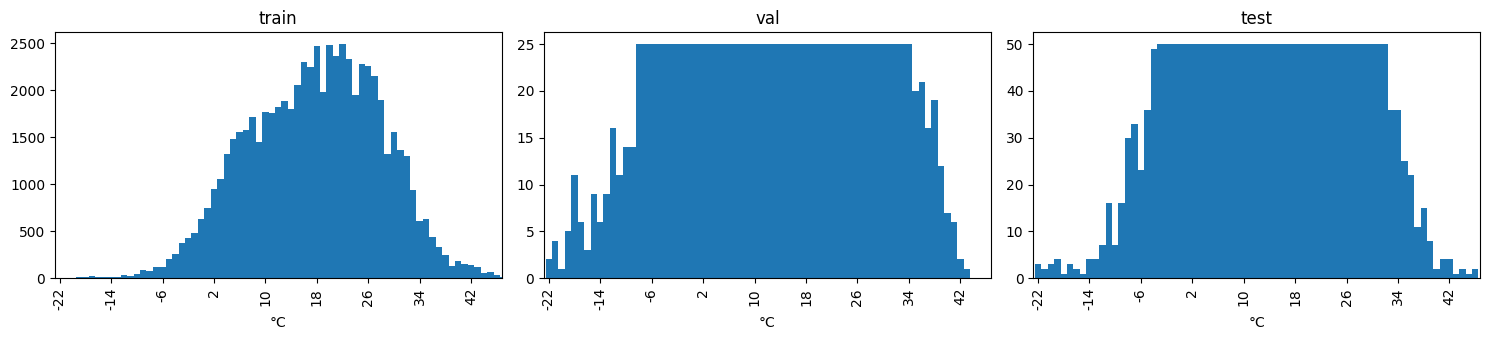

In [18]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
df = pd.read_csv("data/skyfinder.csv")
print(f"rows: {len(df):,}   cameras: {df.CamId.nunique()}")
print(df.groupby("split").agg(n=("temp_c","size"), tmin=("temp_c","min"), tmax=("temp_c","max"),
                              cams=("CamId","nunique"), night=("is_night","mean")).round(2))

train_counts = df[df.split=="train"].temp_c.round().value_counts()
groups = pd.cut(train_counts, [-1, 19, 100, np.inf], labels=["few (<20)", "medium (20-100)", "many (>100)"])
print("\n1°C bins per shot group (train):"); print(groups.value_counts())
print("few-shot bins:", sorted(train_counts[train_counts < 20].index.astype(int)))

# image files actually present?
def found(p):
    cands = [p, os.path.join(IMAGES_DIR, p), os.path.join(IMAGES_DIR, p.split("/", 1)[-1])]
    return any(os.path.exists(c) for c in cands)
print("example path in CSV:", df.path.iloc[0])
missing = sum(not found(p) for p in df.path.sample(min(500, len(df)), random_state=0))
print(f"\nspot check: {missing}/500 sampled paths not found (should be 0 - if not, path prefix mismatch)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for a, s in zip(ax, ["train", "val", "test"]):
    df[df.split==s].temp_c.round().value_counts().sort_index().plot.bar(ax=a, width=1)
    a.set_title(s); a.set_xlabel("°C"); a.xaxis.set_major_locator(plt.MaxNLocator(10))
plt.tight_layout(); plt.show()

## Next
Paste the output of step 7 back into the chat. If it looks right, the next notebook adapts the DIR
training code (Step 3) and runs the vanilla baseline.